# Weak formulation, Galerkin projection and FEM assembly

**Source:** CompSci §§5.4–5.4.4, pp. 49–58 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For steady heat with homogeneous Dirichlet boundaries, $-T''=f$ on $(0,1)$. Multiplying by a test function $v$ and integrating by parts gives $a(T,v)=\int T'v'=\int fv$; the boundary term vanishes. Work in $H^1_0(0,1)$, whose functions have a square-integrable weak derivative and zero boundary trace. Ritz–Galerkin restricts both solution and tests to the same finite space $V_h$. For continuous piecewise linear functions the nodal hats satisfy $\phi_i(x_j)=\delta_{ij}$; in 2D analogous basis functions live on triangles.

Each element of length $\ell$ contributes $\ell^{-1}\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$ and load entries $\int_e f\phi_i$. Assemble by adding entries at shared global nodes, then eliminate the prescribed endpoint values. The interior matrix is symmetric positive definite since $a(v,v)=\int|v'|^2$ and a constant with zero endpoints is zero. Unlike this steady example, time-dependent FEM also has a mass matrix with entries $\int\phi_i\phi_j$.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


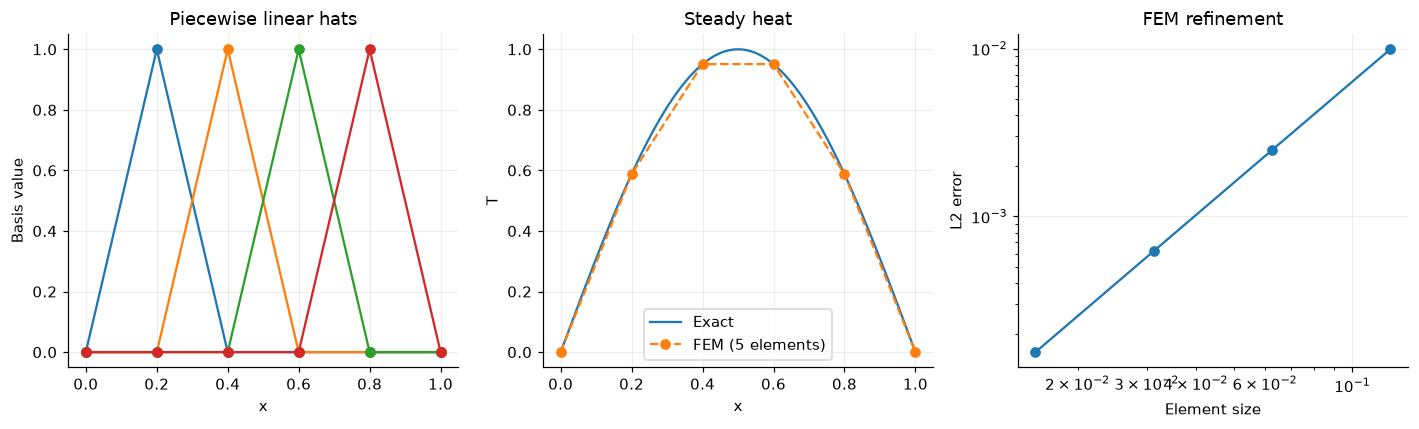

Observed FEM L2 order: 1.9997017191749327


In [2]:
def solve(n):
    nodes=np.linspace(0,1,n+1); h=1/n
    K=np.zeros((n+1,n+1)); b=np.zeros(n+1)
    xi=np.array([.5-.5/np.sqrt(3),.5+.5/np.sqrt(3)])
    for j in range(n):
        f=np.pi**2*np.sin(np.pi*(nodes[j]+h*xi))
        K[j:j+2,j:j+2]+=np.array([[1,-1],[-1,1]])/h
        b[j:j+2]+=h/2*np.array([(1-xi)@f,xi@f])
    interior=K[1:-1,1:-1]
    y=np.r_[0,np.linalg.solve(interior,b[1:-1]),0]
    assert np.allclose(interior@y[1:-1],b[1:-1])
    assert np.allclose(interior,interior.T) and np.min(np.linalg.eigvalsh(interior))>0
    return nodes,y
x=np.linspace(0,1,1601); truth=np.sin(np.pi*x)
ns=np.array([8,16,32,64]); errors=[]
for n in ns:
    nodes,y=solve(n)
    err=np.interp(x,nodes,y)-truth
    errors.append(np.sqrt(np.trapezoid(err*err,x)))
fig,ax=plt.subplots(1,3,figsize=(13,4))
nodes,y=solve(5)
for j in range(1,5):
    ax[0].plot(nodes,np.eye(6)[j],"o-")
ax[0].set(xlabel="x",ylabel="Basis value",title="Piecewise linear hats")
ax[1].plot(x,truth,label="Exact"); ax[1].plot(nodes,y,"o--",label="FEM (5 elements)")
ax[1].set(xlabel="x",ylabel="T",title="Steady heat"); ax[1].legend()
ax[2].loglog(1/ns,errors,"o-")
ax[2].set(xlabel="Element size",ylabel="L2 error",title="FEM refinement")
show(fig,"08-fem")
rate=np.log2(errors[-2]/errors[-1]); assert 1.95<rate<2.05
print("Observed FEM L2 order:",rate)

## Worked exercise

**Why is each hat supported only on neighbouring elements?** It equals one at its own node and zero at adjacent nodes, and is linear between nodes. The derivatives overlap only for equal or neighbouring indices, so the stiffness matrix is tridiagonal in 1D. Dense assembly here is for clarity; larger meshes should use sparse matrices.

## Additional experiment

A quadratic exact solution with constant forcing.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

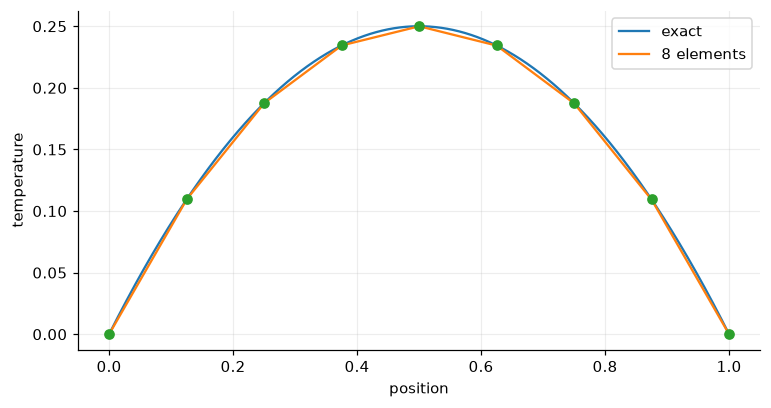

L2 errors: [np.float64(0.002852721653651987), np.float64(0.0007131804133351623), np.float64(0.00017829510302283484), np.float64(4.457377451147418e-05)]
orders: [2.         2.         2.00000004]


In [4]:
errors=[]
for N in [8,16,32,64]:
 x=np.linspace(0,1,N+1);K=np.zeros((N+1,N+1));b=np.zeros(N+1)
 for e in range(N):
  h=x[e+1]-x[e];ids=[e,e+1]
  K[np.ix_(ids,ids)]+=np.array([[1,-1],[-1,1]])/h
  b[ids]+=h # f=2, exact element load
 U=np.zeros(N+1);U[1:-1]=np.linalg.solve(K[1:-1,1:-1],b[1:-1])
 fine=np.linspace(0,1,4097);uh=np.interp(fine,x,U);exact=fine*(1-fine)
 errors.append(np.sqrt(np.trapezoid((uh-exact)**2,fine)))
 if N==8:plt.plot(fine,exact,label="exact");plt.plot(fine,uh,label="8 elements");plt.plot(x,U,"o")
 assert np.linalg.norm(K[1:-1,1:-1]@U[1:-1]-b[1:-1])<1e-10
plt.xlabel("position");plt.ylabel("temperature");plt.legend();plt.show()
print("L2 errors:",errors);print("orders:",np.log2(np.array(errors[:-1])/errors[1:]));assert np.all(np.diff(errors)<0)

## Further practice

Use a nonuniform mesh. Derive the local load for nonconstant f and use quadrature. Explain what changes for a prescribed boundary flux.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.